In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score)
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [8]:
df = pd.read_excel("OnlineRetail.xlsx", sheet_name="Online Retail")
print(df.shape)
print(df.head())
print(df.info())

(541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       ----------

In [9]:
print("Пропуски:\n", df.isna().sum())

print("\nОтрицательные Quantity (возвраты):", (df['Quantity'] < 0).sum())
print("Нулевые/отрицательные UnitPrice:", (df['UnitPrice'] <= 0).sum())

print("\nСтраны (топ-10):")
print(df['Country'].value_counts().head(10))

cancelled = df['InvoiceNo'].astype(str).str.startswith('C')
print("\nОтменённых счетов:", cancelled.sum())

Пропуски:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Отрицательные Quantity (возвраты): 10624
Нулевые/отрицательные UnitPrice: 2517

Страны (топ-10):
Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

Отменённых счетов: 9288


In [10]:
df_clean = df.copy()

df_clean = df_clean.dropna(subset=['CustomerID'])

df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean = df_clean[df_clean['UnitPrice'] > 0]
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

df_clean['TotalSum'] = df_clean['Quantity'] * df_clean['UnitPrice']

print("После очистки:", df_clean.shape)

После очистки: (397884, 9)


In [11]:
orders = df_clean.groupby('InvoiceNo').agg(
    n_items=('Quantity', 'sum'),
    n_lines=('StockCode', 'nunique'),
    total_sum=('TotalSum', 'sum'),
    avg_price=('UnitPrice', 'mean')
).reset_index()
print(orders.shape, orders.describe())

(18532, 5)            InvoiceNo       n_items       n_lines      total_sum     avg_price
count   18532.000000  18532.000000  18532.000000   18532.000000  18532.000000
mean   559527.062487    278.858839     20.928178     480.865956      6.418372
std     13040.177914    972.718727     23.816197    1678.195579     91.915076
min    536365.000000      1.000000      1.000000       0.380000      0.060000
25%    548352.500000     74.000000      6.000000     158.037500      2.011526
50%    559816.500000    155.000000     15.000000     303.040000      2.798477
75%    570834.500000    291.000000     27.000000     471.840000      3.928616
max    581587.000000  80995.000000    541.000000  168469.600000   8142.750000


In [12]:
snapshot = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

customers = df_clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalSum', 'sum'),
    n_items=('Quantity', 'sum'),
    avg_basket=('TotalSum', lambda x: x.sum() / df_clean.loc[x.index, 'InvoiceNo'].nunique())
).reset_index()
print(customers.shape, customers.describe())

(4338, 6)          CustomerID      Recency    Frequency       Monetary        n_items  \
count   4338.000000  4338.000000  4338.000000    4338.000000    4338.000000   
mean   15300.408022    92.536422     4.272015    2054.266460    1191.289073   
std     1721.808492   100.014169     7.697998    8989.230441    5046.081546   
min    12346.000000     1.000000     1.000000       3.750000       1.000000   
25%    13813.250000    18.000000     1.000000     307.415000     160.000000   
50%    15299.500000    51.000000     2.000000     674.485000     379.000000   
75%    16778.750000   142.000000     5.000000    1661.740000     992.750000   
max    18287.000000   374.000000   209.000000  280206.020000  196915.000000   

         avg_basket  
count   4338.000000  
mean     419.166289  
std     1796.537944  
min        3.450000  
25%      178.625000  
50%      293.900000  
75%      430.113750  
max    84236.250000  


In [13]:
def remove_outliers_iqr(data, cols, k=1.5):
    mask = pd.Series(True, index=data.index)
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        mask &= data[c].between(q1 - k*iqr, q3 + k*iqr)
    return data[mask].copy()

order_feats = ['n_items', 'total_sum', 'avg_price']
orders_f = remove_outliers_iqr(orders, order_feats, k=1.5)
print("Заказы после выбросов:", orders_f.shape)

scaler_o = StandardScaler()
X_orders = scaler_o.fit_transform(orders_f[order_feats])

rfm_feats = ['Recency', 'Frequency', 'Monetary']
customers_f = remove_outliers_iqr(customers, rfm_feats, k=1.5)
print("Клиенты после выбросов:", customers_f.shape)

scaler_c = StandardScaler()
X_cust = scaler_c.fit_transform(customers_f[rfm_feats])

Заказы после выбросов: (15679, 5)
Клиенты после выбросов: (3710, 6)


In [14]:
def eval_kmeans(X, k_range):
    res = []
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=10, random_state=42)
        labels = km.fit_predict(X)
        res.append({
            'k': k,
            'inertia': km.inertia_,
            'silhouette': silhouette_score(X, labels),
            'davies_bouldin': davies_bouldin_score(X, labels),
            'calinski_harabasz': calinski_harabasz_score(X, labels)
        })
    return pd.DataFrame(res)

km_orders = eval_kmeans(X_orders, range(2, 9))
print("K-Means по заказам:\n", km_orders.to_string(index=False))

km_cust = eval_kmeans(X_cust, range(2, 9))
print("K-Means по клиентам:\n", km_cust.to_string(index=False))

K-Means по заказам:
  k      inertia  silhouette  davies_bouldin  calinski_harabasz
 2 27919.245165    0.380664        1.050123       10734.915031
 3 19194.799048    0.358763        0.943874       11369.132262
 4 15027.052669    0.343879        0.960813       11130.138503
 5 12650.400057    0.341634        0.945512       10651.442555
 6 10996.354968    0.317328        0.946697       10273.723142
 7  9630.260431    0.307347        0.955397       10145.891768
 8  8582.555242    0.314653        0.958371       10030.791560
K-Means по клиентам:
  k     inertia  silhouette  davies_bouldin  calinski_harabasz
 2 6015.489861    0.454081        0.902864        3152.628304
 3 3502.543900    0.459959        0.765886        4036.355482
 4 2706.404332    0.413330        0.900626        3844.940212
 5 2321.451200    0.400403        0.960862        3514.576713
 6 2015.243983    0.368096        0.991920        3350.574572
 7 1776.207612    0.355065        0.978560        3250.121700
 8 1613.285533    0

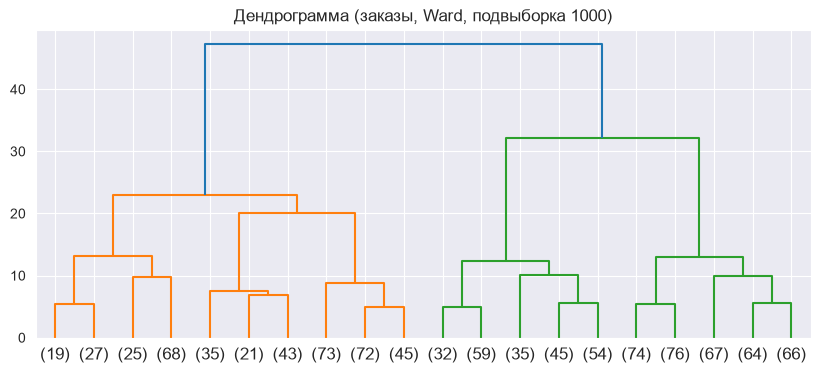

Иерархическая по заказам:
   method  k  silhouette  davies_bouldin  calinski_harabasz
 average  2    0.409889        0.958493        8229.673575
    ward  2    0.386495        1.025364        9605.922458
 average  3    0.355868        0.884256        4882.984244
    ward  3    0.341809        0.944071        9017.202267
 average  4    0.291147        0.859951        5453.473074
complete  3    0.282739        1.093408        7508.359946
 average  5    0.281331        0.857447        4102.939870
    ward  5    0.268939        1.154289        8202.201459
Иерархическая по клиентам:
   method  k  silhouette  davies_bouldin  calinski_harabasz
    ward  2    0.462315        0.872394        2808.763677
    ward  3    0.444293        0.786714        3695.311949
complete  2    0.427255        0.932703        2730.695909
 average  3    0.417676        0.774008        1191.623334
 average  4    0.398907        0.841967         798.887493
 average  6    0.384325        0.886750        1541.457943
 

In [15]:
sample_o = X_orders[np.random.choice(len(X_orders), size=min(1000, len(X_orders)), replace=False)]
plt.figure(figsize=(10, 4))
dendrogram(linkage(sample_o, method='ward'), truncate_mode='lastp', p=20)
plt.title('Дендрограмма (заказы, Ward, подвыборка 1000)')
plt.show()

def eval_agglo(X, k_range, method='ward'):
    res = []
    for k in k_range:
        agg = AgglomerativeClustering(n_clusters=k, linkage=method)
        labels = agg.fit_predict(X)
        res.append({
            'method': method, 'k': k,
            'silhouette': silhouette_score(X, labels),
            'davies_bouldin': davies_bouldin_score(X, labels),
            'calinski_harabasz': calinski_harabasz_score(X, labels)
        })
    return pd.DataFrame(res)

agg_orders = pd.concat([eval_agglo(X_orders, range(2, 8), m)
                        for m in ['ward', 'complete', 'average']])
agg_cust = pd.concat([eval_agglo(X_cust, range(2, 8), m)
                      for m in ['ward', 'complete', 'average']])

print("Иерархическая по заказам:\n",
      agg_orders.sort_values('silhouette', ascending=False).head(8).to_string(index=False))
print("Иерархическая по клиентам:\n",
      agg_cust.sort_values('silhouette', ascending=False).head(8).to_string(index=False))

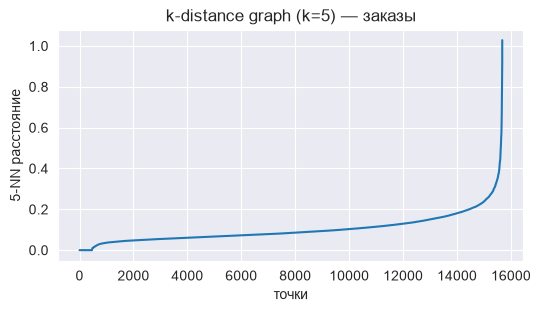

DBSCAN по заказам:
  eps  min_samples  n_clusters  noise_ratio  silhouette  davies_bouldin  calinski_harabasz
 0.3           20           2     0.057083    0.408395        0.448609          95.572943
 0.3           10           2     0.022706    0.293039        0.608440          38.991753
 0.3            5           6     0.009184    0.197221        0.584224          21.943991
 0.3           15           1     0.039288         NaN             NaN                NaN
 0.5            5           1     0.001786         NaN             NaN                NaN
 0.5           10           1     0.003253         NaN             NaN                NaN
 0.5           15           1     0.004273         NaN             NaN                NaN
 0.5           20           1     0.005549         NaN             NaN                NaN
 0.7            5           1     0.000319         NaN             NaN                NaN
 0.7           10           1     0.000765         NaN             NaN          

In [16]:
def eval_dbscan(X, eps_grid, min_samples_grid):
    res = []
    for eps in eps_grid:
        for ms in min_samples_grid:
            db = DBSCAN(eps=eps, min_samples=ms)
            labels = db.fit_predict(X)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            noise_ratio = (labels == -1).mean()
            if n_clusters >= 2:
                # силуэт считаем только по не-шумовым точкам
                mask = labels != -1
                sil = silhouette_score(X[mask], labels[mask]) if mask.sum() > 10 else np.nan
                db_idx = davies_bouldin_score(X[mask], labels[mask]) if mask.sum() > 10 else np.nan
                ch = calinski_harabasz_score(X[mask], labels[mask]) if mask.sum() > 10 else np.nan
            else:
                sil = db_idx = ch = np.nan
            res.append({'eps': eps, 'min_samples': ms,
                        'n_clusters': n_clusters,
                        'noise_ratio': noise_ratio,
                        'silhouette': sil,
                        'davies_bouldin': db_idx,
                        'calinski_harabasz': ch})
    return pd.DataFrame(res)

from sklearn.neighbors import NearestNeighbors
k = 5
nbrs = NearestNeighbors(n_neighbors=k).fit(X_orders)
dist, _ = nbrs.kneighbors(X_orders)
kdist = np.sort(dist[:, -1])
plt.figure(figsize=(6, 3))
plt.plot(kdist); plt.title(f'k-distance graph (k={k}) — заказы')
plt.xlabel('точки'); plt.ylabel(f'{k}-NN расстояние')
plt.show()

db_orders = eval_dbscan(X_orders,
                        eps_grid=[0.3, 0.5, 0.7, 1.0, 1.5],
                        min_samples_grid=[5, 10, 15, 20])
print("DBSCAN по заказам:\n",
      db_orders.sort_values('silhouette', ascending=False).head(10).to_string(index=False))

db_cust = eval_dbscan(X_cust,
                      eps_grid=[0.3, 0.5, 0.7, 1.0, 1.5],
                      min_samples_grid=[5, 10, 15, 20])
print("DBSCAN по клиентам:\n",
      db_cust.sort_values('silhouette', ascending=False).head(10).to_string(index=False))

In [17]:
def best_row(df_res, name):
    r = df_res.loc[df_res['silhouette'].idxmax()].to_dict()
    r['model'] = name
    return r

summary = pd.DataFrame([
    {**best_row(km_orders, 'KMeans / orders'),
     'target': 'orders'},
    {**best_row(agg_orders, 'Agglo / orders'),
     'target': 'orders'},
    {**best_row(db_orders.dropna(subset=['silhouette']), 'DBSCAN / orders'),
     'target': 'orders'},
    {**best_row(km_cust, 'KMeans / customers'),
     'target': 'customers'},
    {**best_row(agg_cust, 'Agglo / customers'),
     'target': 'customers'},
    {**best_row(db_cust.dropna(subset=['silhouette']), 'DBSCAN / customers'),
     'target': 'customers'},
])
cols = ['target', 'model', 'silhouette', 'davies_bouldin', 'calinski_harabasz']
print(summary[cols].to_string(index=False))

   target              model               silhouette          davies_bouldin       calinski_harabasz
   orders    KMeans / orders                 0.380664                1.050123            10734.915031
   orders     Agglo / orders {0: 0.40988940528004036}  {0: 0.958493330205657}  {0: 8229.673575027331}
   orders    DBSCAN / orders                 0.408395                0.448609               95.572943
customers KMeans / customers                 0.459959                0.765886             4036.355482
customers  Agglo / customers  {0: 0.3819588862886877} {0: 0.7032850652694788} {0: 15.593045576758955}
customers DBSCAN / customers                 0.048435                1.674227              421.307965


K-Means (orders), k=2
        n_items        total_sum        avg_price       
           mean  count      mean  count      mean  count
cluster                                                 
0         321.5   5377     499.6   5377       2.6   5377
1         101.1  10302     200.0  10302       3.1  10302


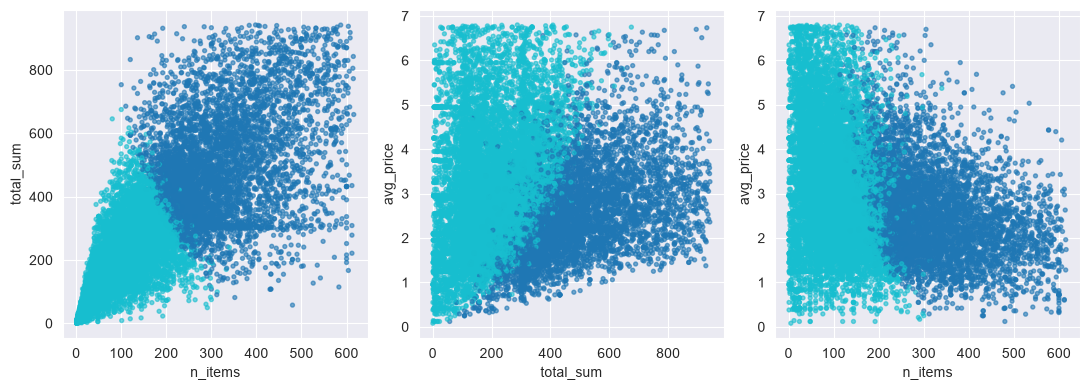

In [18]:
best_k_orders = int(km_orders.loc[km_orders['silhouette'].idxmax(), 'k'])
km_o = KMeans(n_clusters=best_k_orders, n_init=10, random_state=42)
orders_f['cluster'] = km_o.fit_predict(X_orders)

print(f"K-Means (orders), k={best_k_orders}")
print(orders_f.groupby('cluster')[order_feats].agg(['mean', 'count']).round(1))

fig = plt.figure(figsize=(11, 4))
for i, (a, b) in enumerate([('n_items','total_sum'),
                            ('total_sum','avg_price'),
                            ('n_items','avg_price')], 1):
    ax = fig.add_subplot(1, 3, i)
    ax.scatter(orders_f[a], orders_f[b],
               c=orders_f['cluster'], cmap='tab10', s=8, alpha=0.6)
    ax.set_xlabel(a); ax.set_ylabel(b)
plt.tight_layout(); plt.show()

K-Means (customers), k=3
         Recency  Frequency  Monetary  avg_basket  count
cluster                                                 
0           48.8        2.1     598.8       312.1   1968
1          226.8        1.5     414.1       295.2    920
2           36.2        6.0    2107.9       405.5    822


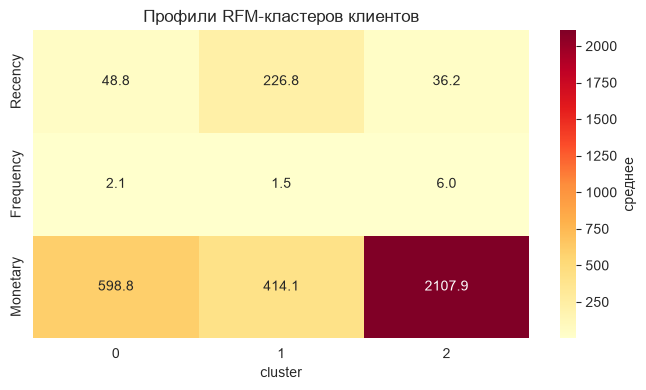

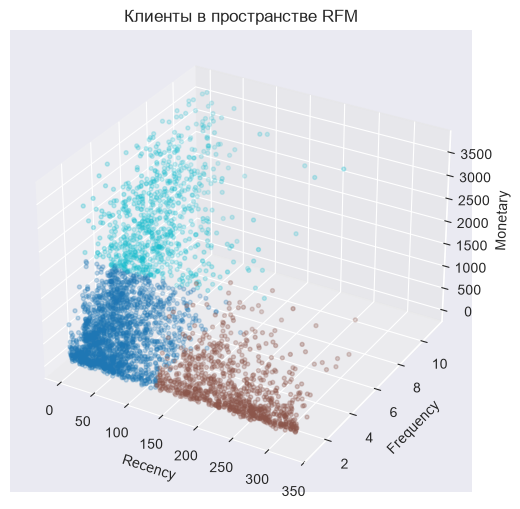

In [19]:

best_k_cust = int(km_cust.loc[km_cust['silhouette'].idxmax(), 'k'])
km_c = KMeans(n_clusters=best_k_cust, n_init=10, random_state=42)
customers_f['cluster'] = km_c.fit_predict(X_cust)

profiles = customers_f.groupby('cluster')[rfm_feats + ['avg_basket']].mean().round(1)
profiles['count'] = customers_f.groupby('cluster').size()
print(f"K-Means (customers), k={best_k_cust}")
print(profiles)


plt.figure(figsize=(8, 4))
sns.heatmap(profiles[rfm_feats].T, annot=True, fmt='.1f',
            cmap='YlOrRd', cbar_kws={'label': 'среднее'})
plt.title('Профили RFM-кластеров клиентов')
plt.show()


from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(customers_f['Recency'], customers_f['Frequency'],
           customers_f['Monetary'], c=customers_f['cluster'],
           cmap='tab10', s=8, alpha=0.6)
ax.set_xlabel('Recency'); ax.set_ylabel('Frequency'); ax.set_zlabel('Monetary')
plt.title('Клиенты в пространстве RFM'); plt.show()